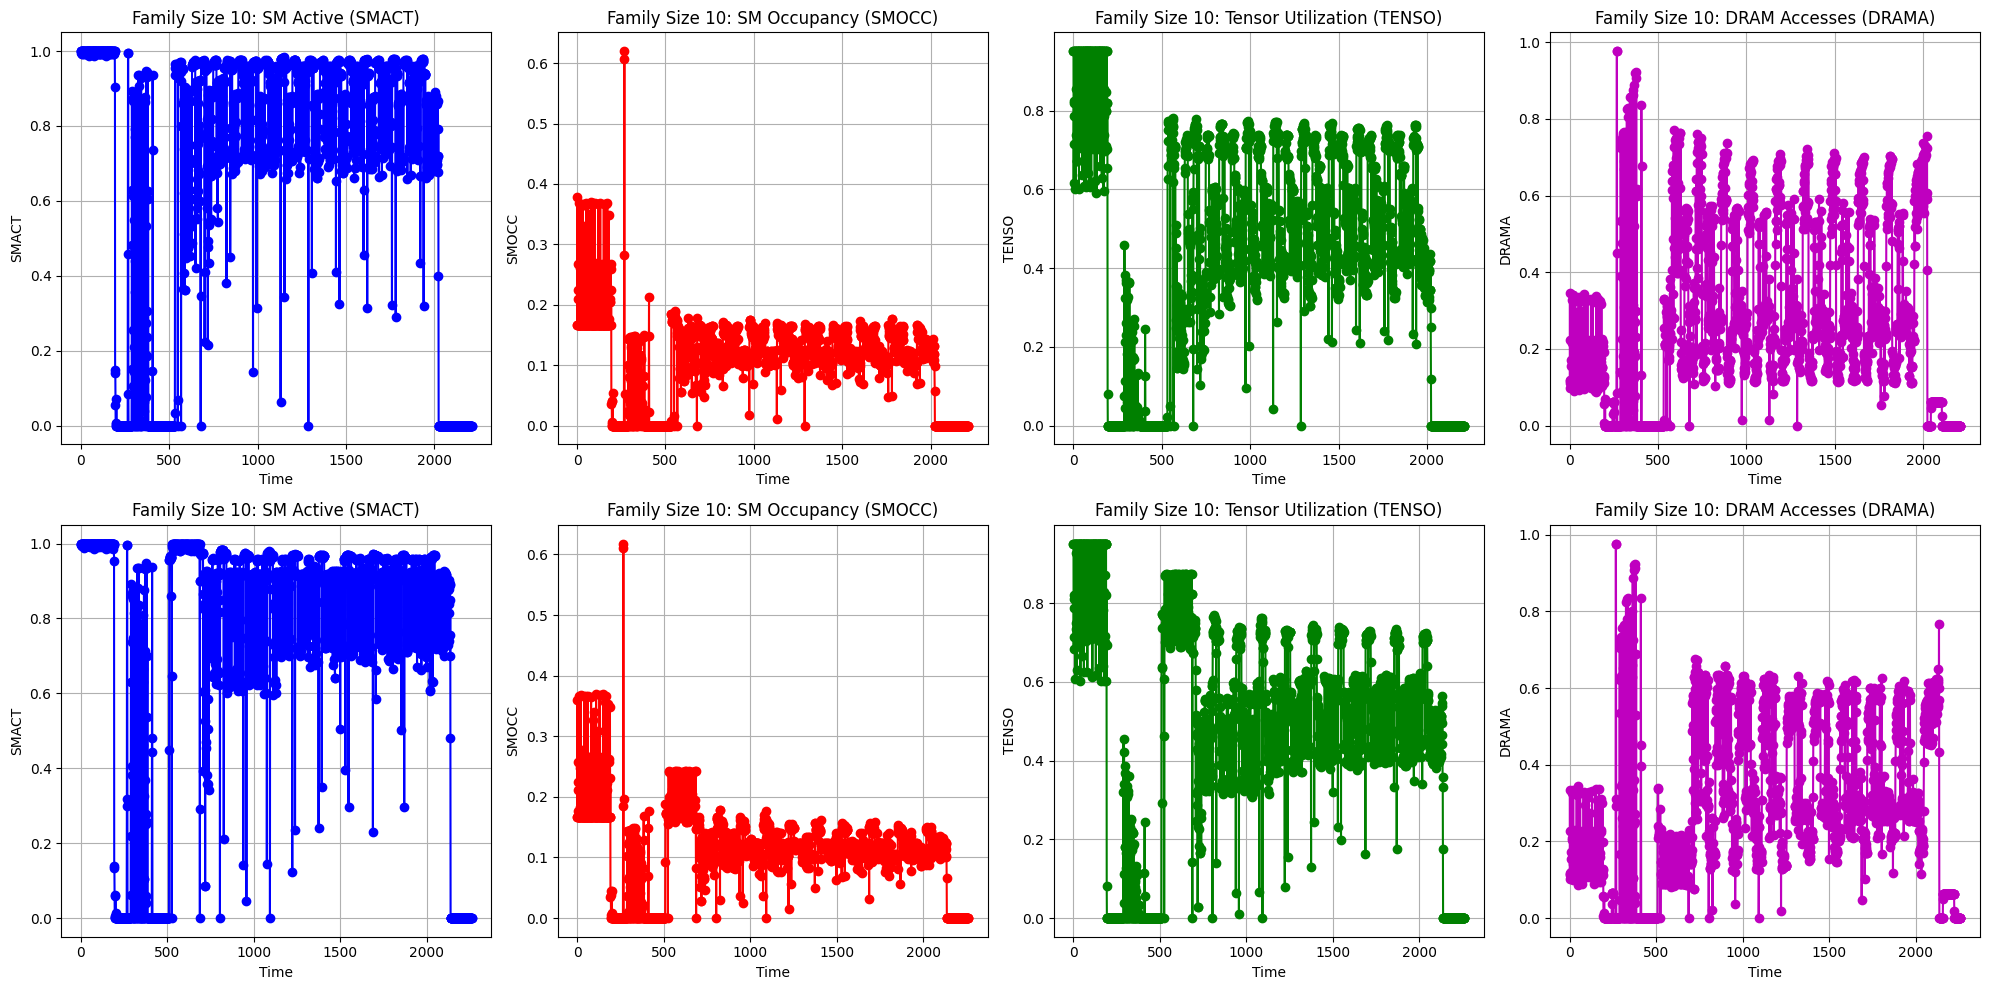

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import re

files = [".out_10_100_not_random", ".out_10_100_random"]

fig, axes = plt.subplots(nrows=len(files), ncols=4, figsize=(20, 10))
fig.subplots_adjust(hspace=0.4, wspace=0.3)

for i, file_path in enumerate(files):
    match = re.search(r"(\d+)", file_path)
    batch_size = match.group(1) if match else "?"
    data = []
    with open(file_path, "r") as f:
        for line in f:
            if line.strip() and not line.startswith("#"):
                parts = line.split()
                if len(parts) >= 4 and len(parts) <= 7:
                    smact = parts[2]
                    smocc = parts[3]
                    tenso = parts[4]
                    drama = parts[5]
                    try:
                        data.append((float(smact), float(smocc), float(tenso), float(drama)))
                    except ValueError:
                        continue

    df = pd.DataFrame(data, columns=["SMACT", "SMOCC", "TENSO", "DRAMA"])

    # --- Plot SMACT ---
    ax1 = axes[i, 0]
    ax1.plot(df["SMACT"], marker='o', linestyle='-', color='b')
    ax1.set_title(f"Family Size {batch_size}: SM Active (SMACT)")
    ax1.set_xlabel("Time")
    ax1.set_ylabel("SMACT")
    ax1.grid(True)

    # --- Plot SMOCC ---
    ax2 = axes[i, 1]
    ax2.plot(df["SMOCC"], marker='o', linestyle='-', color='r')
    ax2.set_title(f"Family Size {batch_size}: SM Occupancy (SMOCC)")
    ax2.set_xlabel("Time")
    ax2.set_ylabel("SMOCC")
    ax2.grid(True)

    # --- Plot TENSO ---
    ax3 = axes[i, 2]
    ax3.plot(df["TENSO"], marker='o', linestyle='-', color='g')
    ax3.set_title(f"Family Size {batch_size}: Tensor Utilization (TENSO)")
    ax3.set_xlabel("Time")
    ax3.set_ylabel("TENSO")
    ax3.grid(True)  

    # --- Plot DRAMA ---
    ax4 = axes[i, 3]
    ax4.plot(df["DRAMA"], marker='o', linestyle='-', color='m')
    ax4.set_title(f"Family Size {batch_size}: DRAM Accesses (DRAMA)")
    ax4.set_xlabel("Time")
    ax4.set_ylabel("DRAMA")
    ax4.grid(True)
plt.tight_layout()
plt.show()
# plt.savefig("../../results/smact_smocc_tenso_family_sizes_batch_size_500.png")
# plt.savefig("../../results/smact_smocc_batch_sizes.png")

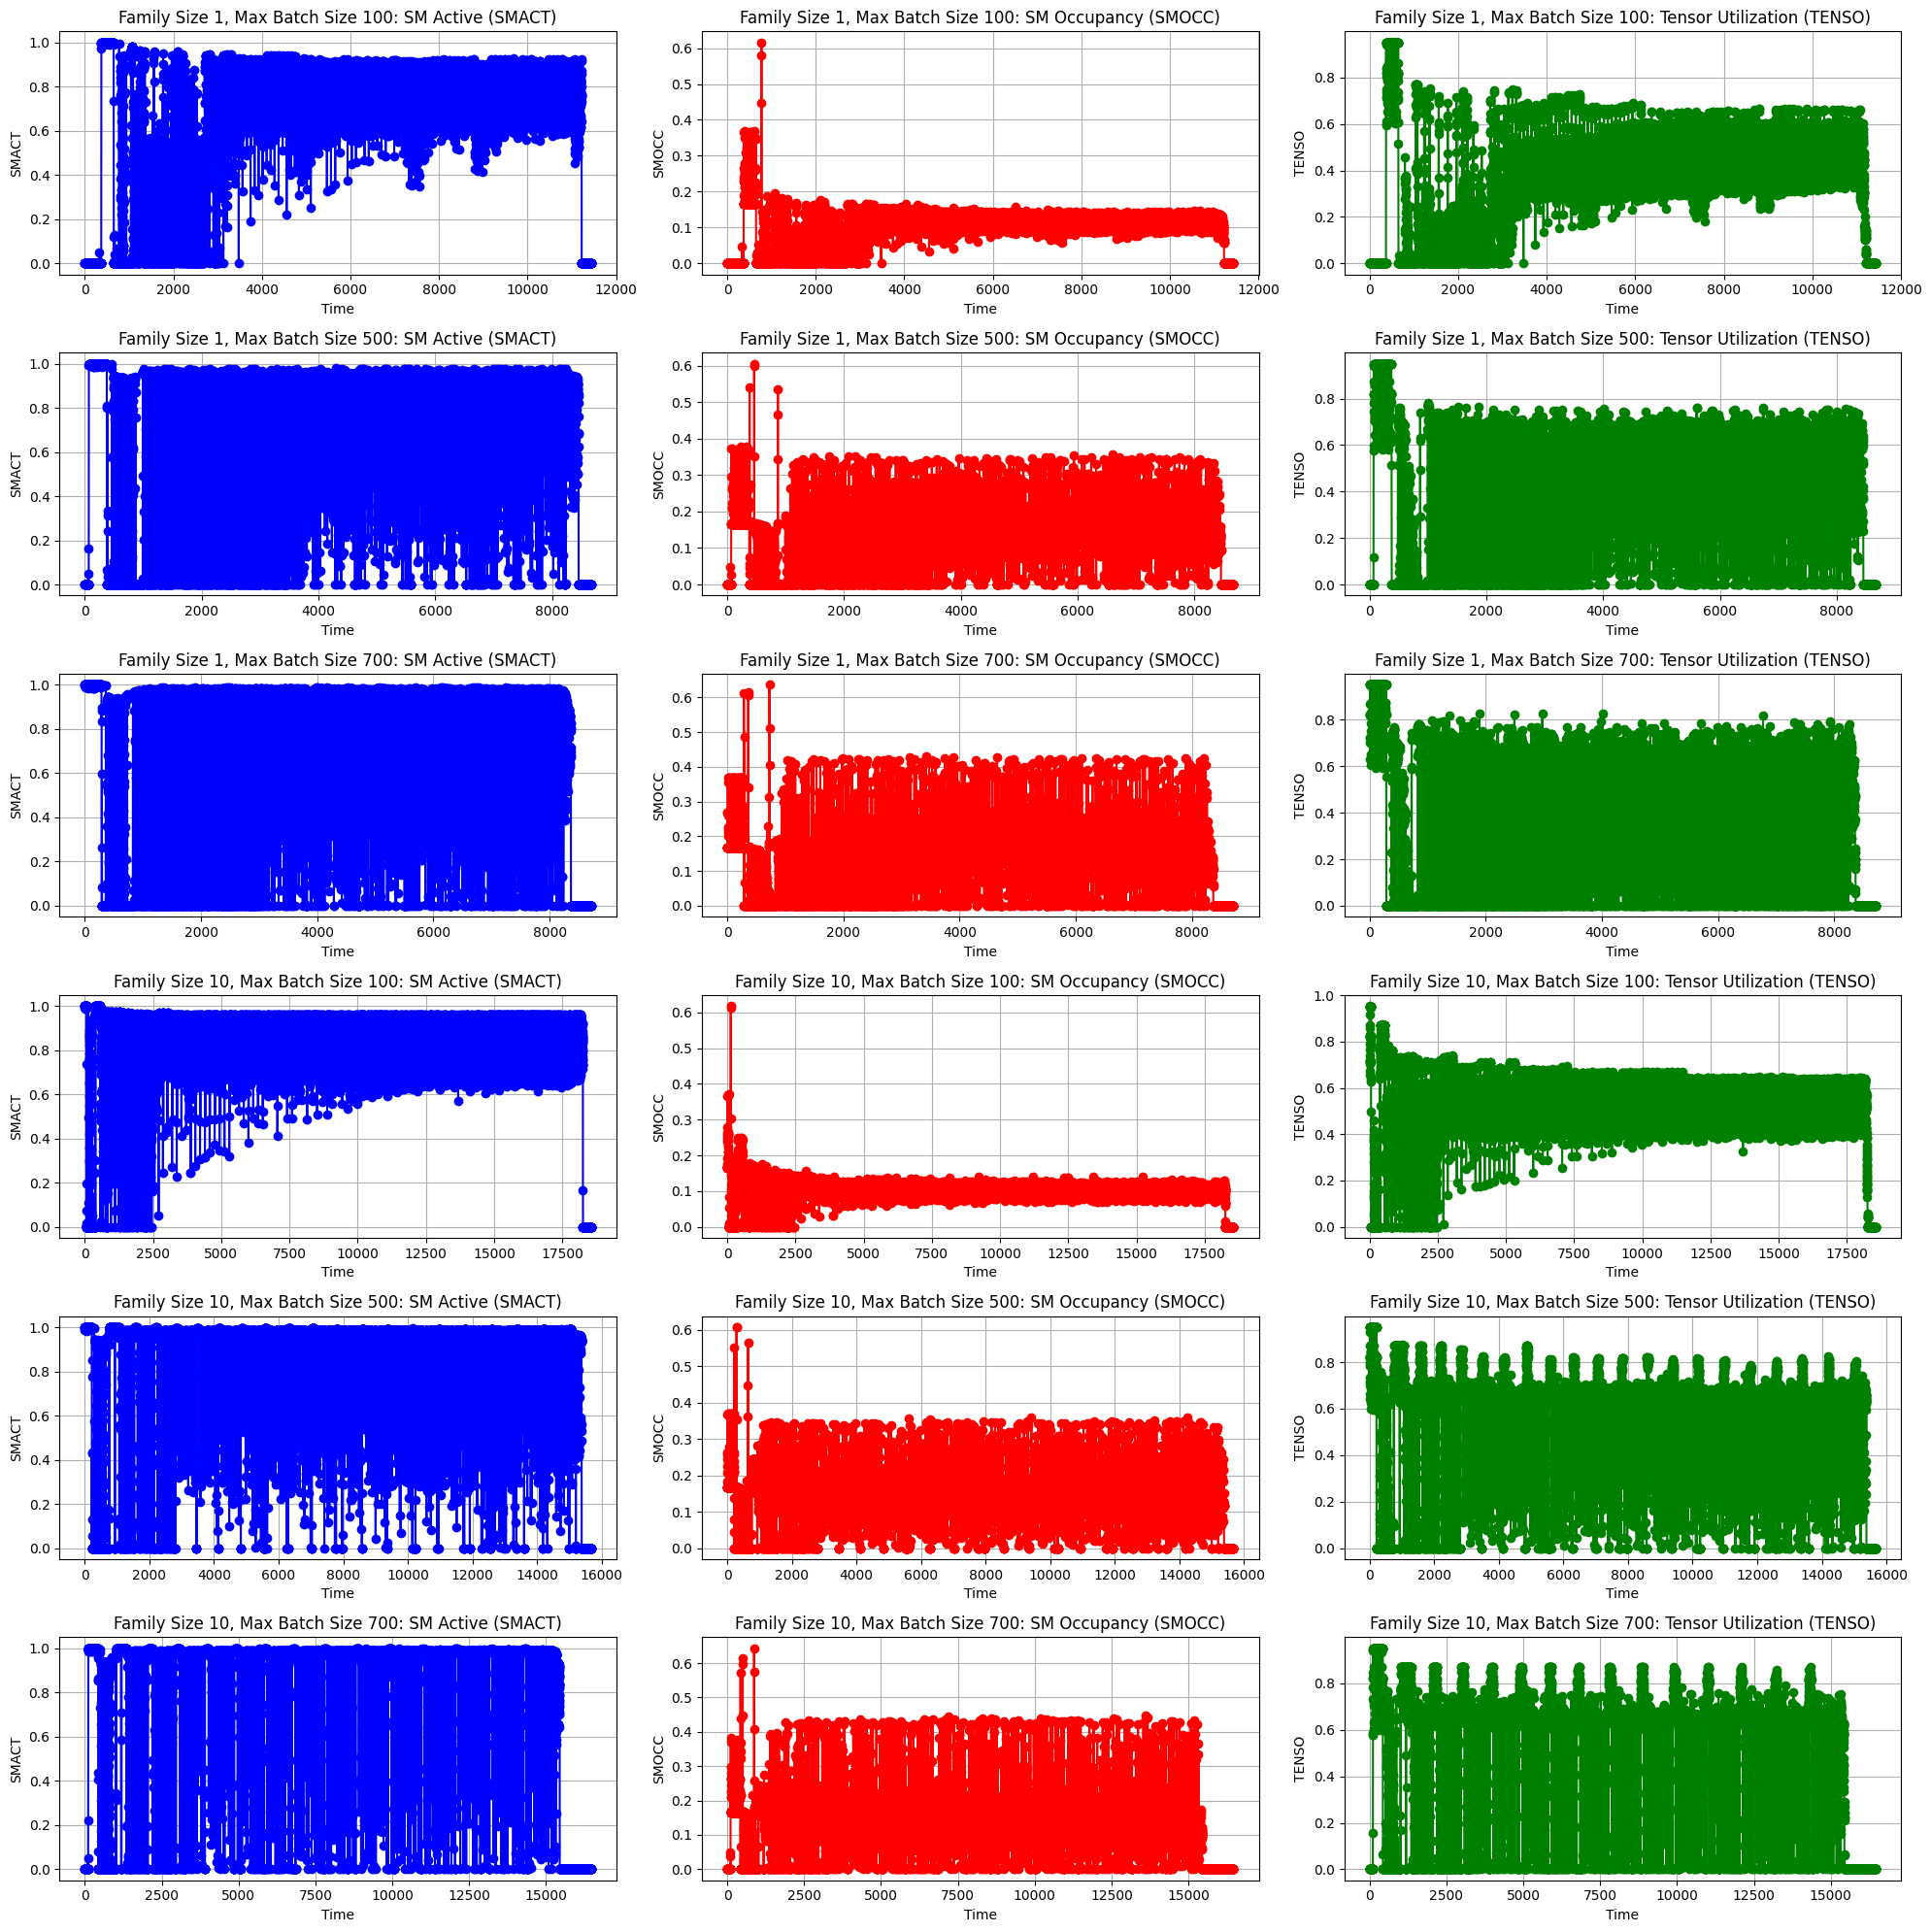

<Figure size 640x480 with 0 Axes>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import re

files = [".out_1_100", ".out_1_500", ".out_1_700", ".out_10_100", ".out_10_500", ".out_10_700"]

fig, axes = plt.subplots(nrows=len(files), ncols=3, figsize=(20,20))
fig.subplots_adjust(hspace=0.4, wspace=0.3)

for i, file_path in enumerate(files):
    # Extract batch size (last number in the filename)
    match = re.search(r"(\d+)", file_path)
    family_size = match.group(1) if match else "?"
    batch_size = re.search(r"_(\d+)$", file_path).group(1) if re.search(r"_(\d+)$", file_path) else "?"

    data = []
    with open(file_path, "r") as f:
        for line in f:
            if line.strip() and not line.startswith("#"):
                parts = line.split()
                if len(parts) >= 5 and len(parts) <= 7:
                    smact = parts[2]
                    smocc = parts[3]
                    tenso = parts[4]
                    try:
                        data.append((float(smact), float(smocc), float(tenso)))
                    except ValueError:
                        continue

    df = pd.DataFrame(data, columns=["SMACT", "SMOCC", "TENSO"])

    ax1 = axes[i, 0]
    ax1.plot(df["SMACT"], marker='o', linestyle='-', color='b')
    ax1.set_title(f"Family Size {family_size}, Max Batch Size {batch_size}: SM Active (SMACT)")
    ax1.set_xlabel("Time")
    ax1.set_ylabel("SMACT")
    ax1.grid(True)

    ax2 = axes[i, 1]
    ax2.plot(df["SMOCC"], marker='o', linestyle='-', color='r')
    ax2.set_title(f"Family Size {family_size}, Max Batch Size {batch_size}: SM Occupancy (SMOCC)")
    ax2.set_xlabel("Time")
    ax2.set_ylabel("SMOCC")
    ax2.grid(True)

    ax3 = axes[i, 2]
    ax3.plot(df["TENSO"], marker='o', linestyle='-', color='g')
    ax3.set_title(f"Family Size {family_size}, Max Batch Size {batch_size}: Tensor Utilization (TENSO)")
    ax3.set_xlabel("Time")
    ax3.set_ylabel("TENSO")
    ax3.grid(True)  
plt.tight_layout()
plt.show()
plt.savefig("../../results/smact_smocc_tenso_different_family_batches.png")

/tmp/ipykernel_2073265/1358078537.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap('tab20', len(groups))  # or try 'husl', 'viridis', etc.


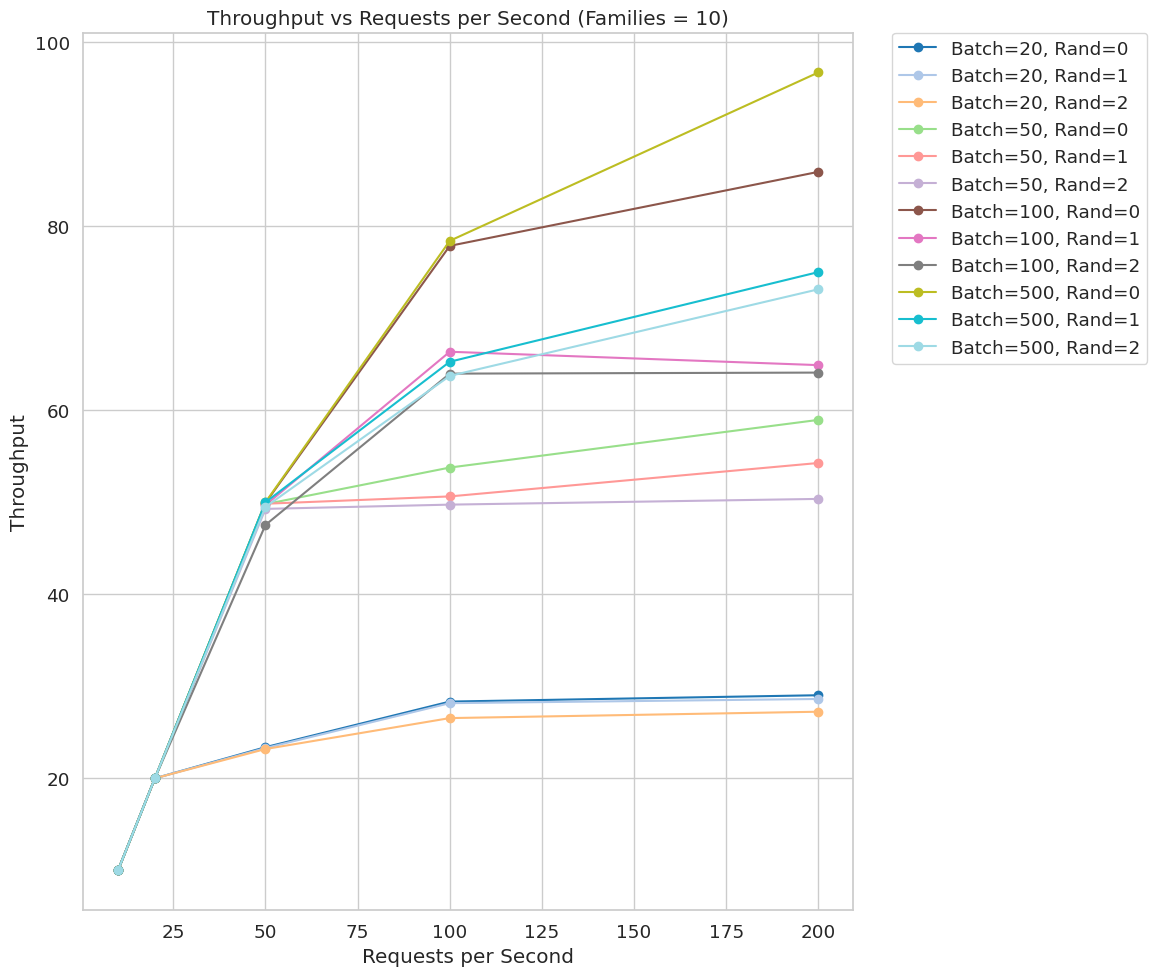

/tmp/ipykernel_2073265/1358078537.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap('tab20', len(groups))  # or try 'husl', 'viridis', etc.


<Figure size 640x480 with 0 Axes>

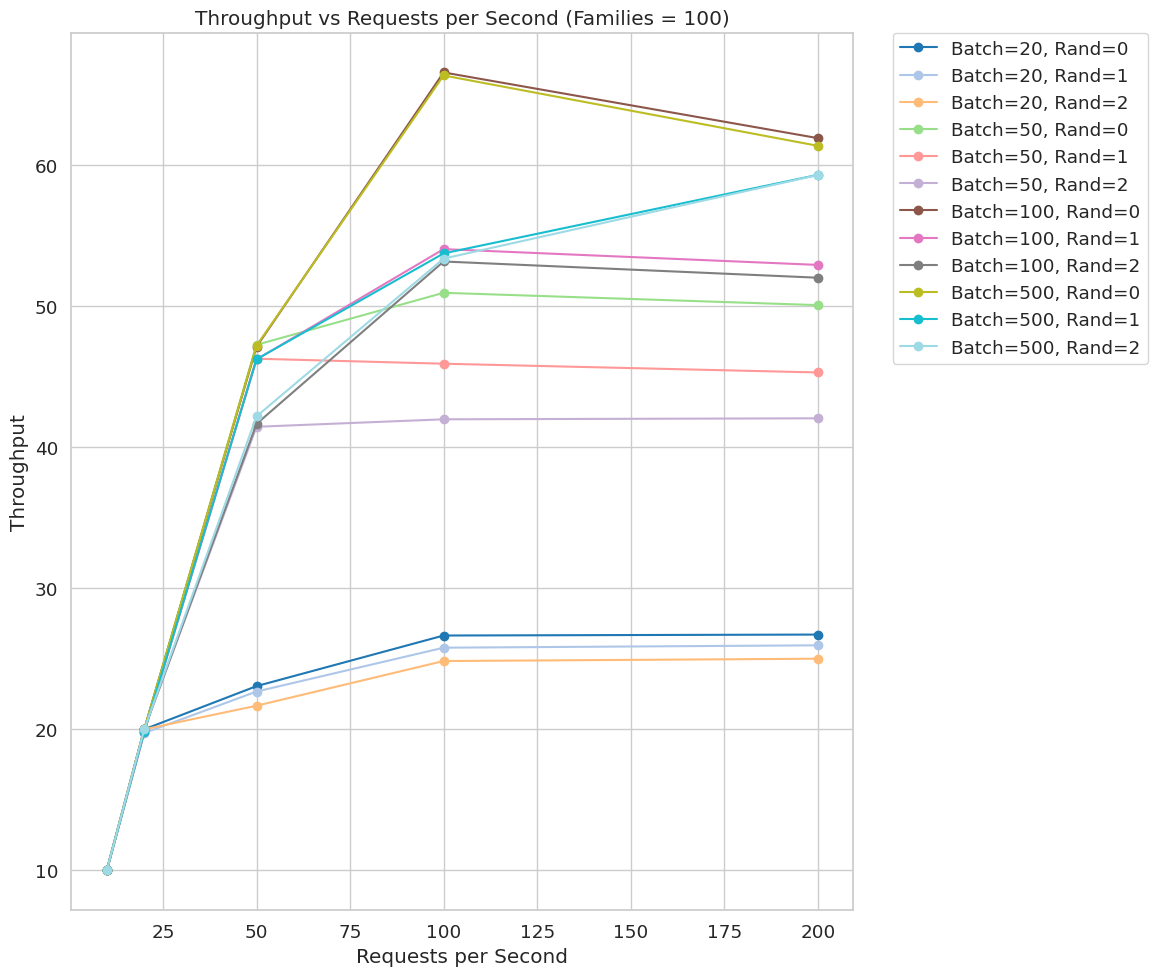

<Figure size 640x480 with 0 Axes>

In [6]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------- READ AND PARSE ----------
data = []
pattern = re.compile(
    r"Throughput Test with (\d+) families, (\d+) req/sec and max_batch_size of (\d+) \(randomness: (\d+)\): ([\d\.]+)"
)

tuple_to_throughput = {}

with open("vllm_multiple_families_varying_workloads_output.txt") as f:
    for line in f:
        m = pattern.search(line)
        if m:
            families, req, batch, rand, value = m.groups()
            tuple_to_throughput[(int(families), int(req), int(batch), int(rand))] = float(value)
for (key, value) in tuple_to_throughput.items():
    families, req, batch, rand = key
    data.append({
        "families": families,
        "req_per_sec": req,
        "batch_size": batch,
        "randomness": rand,
        "throughput": value
    })

df = pd.DataFrame(data)

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

# ---------- PLOT: Separate for each number of families ----------
for families, df_fam in df.groupby("families"):
    plt.figure(figsize=(15, 10))
    groups = list(df_fam.groupby(["batch_size", "randomness"]))
    colors = cm.get_cmap('tab20', len(groups))  # or try 'husl', 'viridis', etc.

    for idx, ((batch, rand), group) in enumerate(groups):
        group = group.sort_values("req_per_sec")
        plt.plot(
            group["req_per_sec"],
            group["throughput"],
            marker="o",
            color=colors(idx),
            label=f"Batch={batch}, Rand={rand}"
        )

    plt.xlabel("Requests per Second")
    plt.ylabel("Throughput")
    plt.title(f"Throughput vs Requests per Second (Families = {families})")
    plt.grid(True)

    # ---- Legend outside plot ----
    plt.legend(
        bbox_to_anchor=(1.05, 1),  # shift legend to right
        loc='upper left',
        borderaxespad=0.
    )

    plt.tight_layout(rect=[0, 0, 0.8, 1])  # leave room for legend
    plt.show()
    plt.savefig(f"../../results/throughput_vs_req_batch_rand_families_{families}.png")




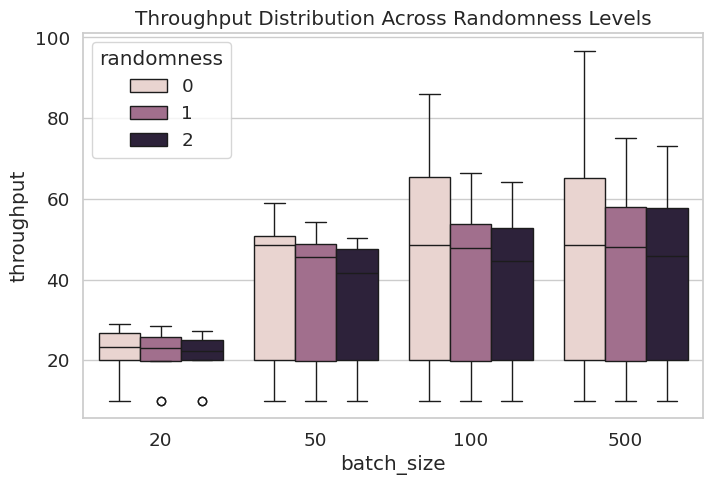

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="batch_size", y="throughput", hue="randomness")
plt.title("Throughput Distribution Across Randomness Levels")
plt.show()
plt.savefig("../../results/throughput_boxplot_batch_size_randomness.png")


   families  req_per_sec  batch_size  randomness framework  throughput
0        10           50          20           0      VLLM   23.705546
1        10           50          20           0    SGLANG   20.959019
2        10           50          20           1      VLLM   23.187095
3        10           50          20           1    SGLANG   19.534493
4        10           50          20           2      VLLM   22.199551


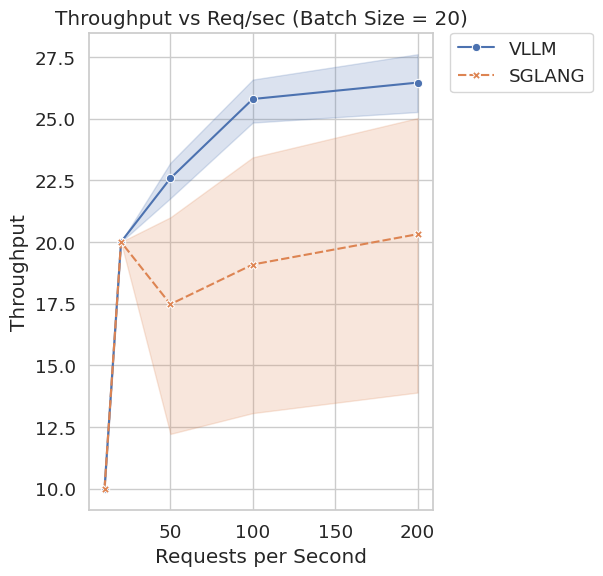

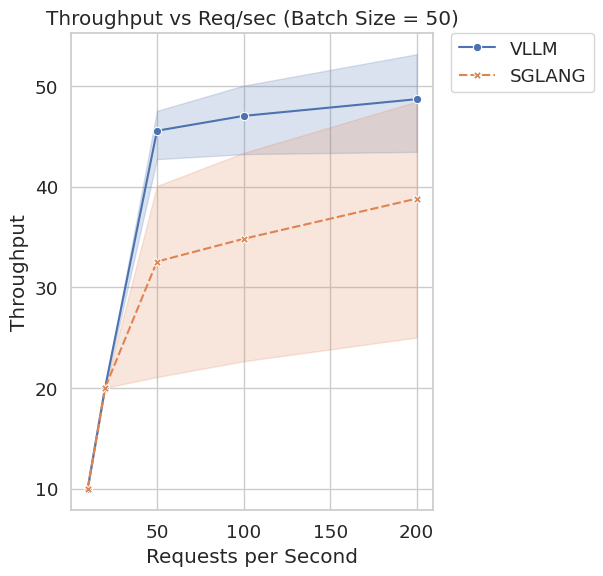

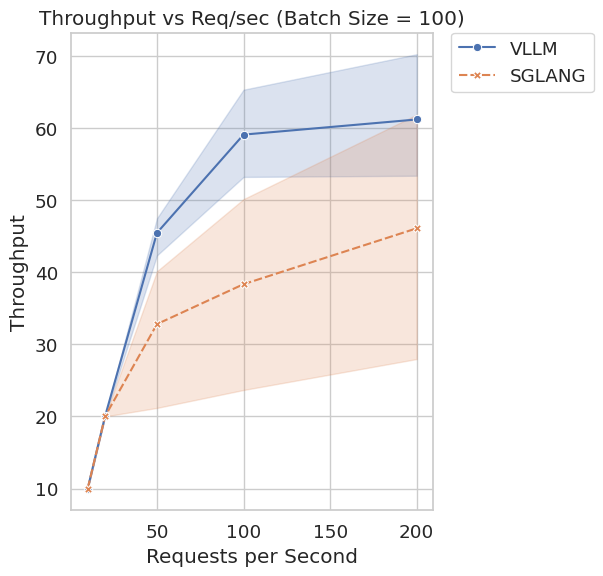

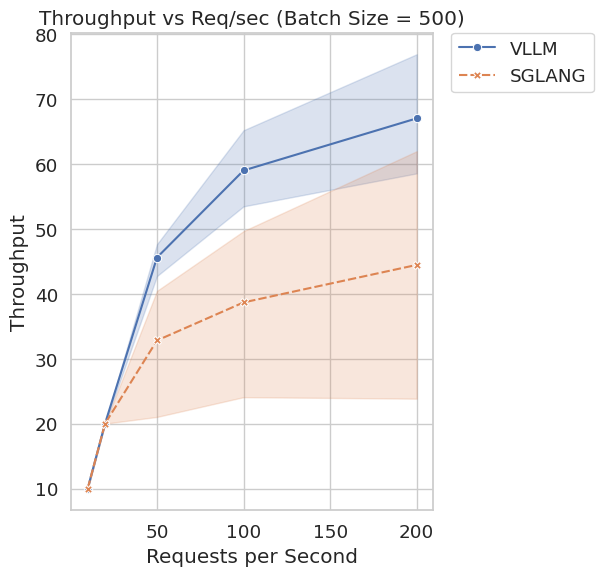

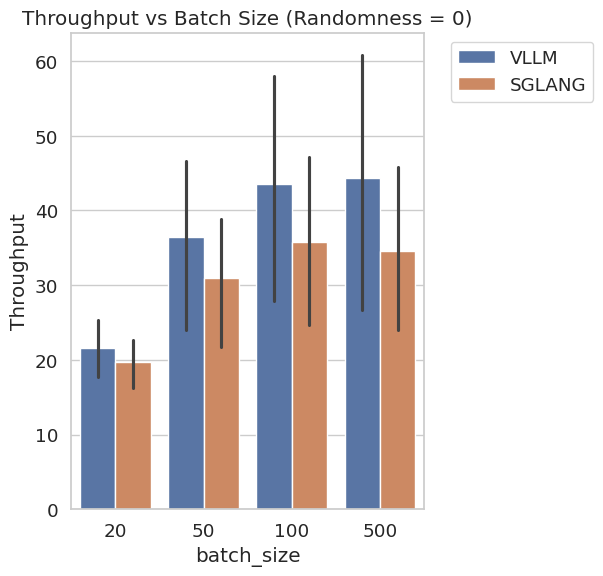

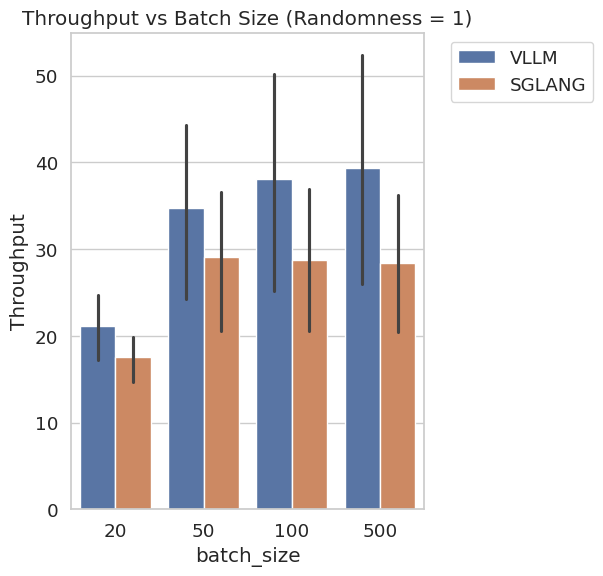

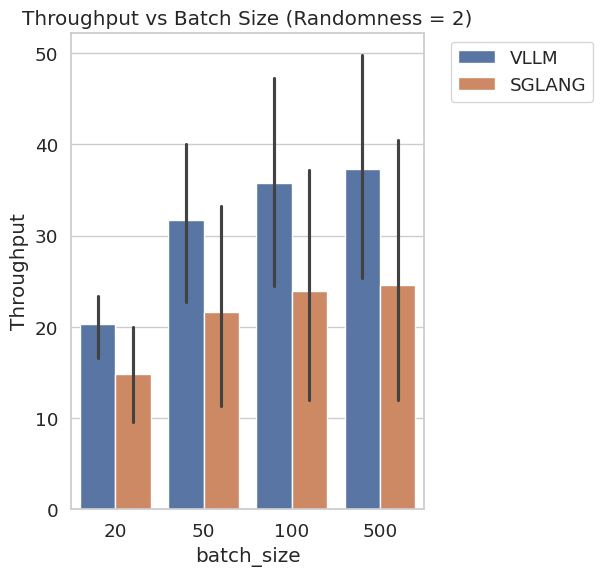

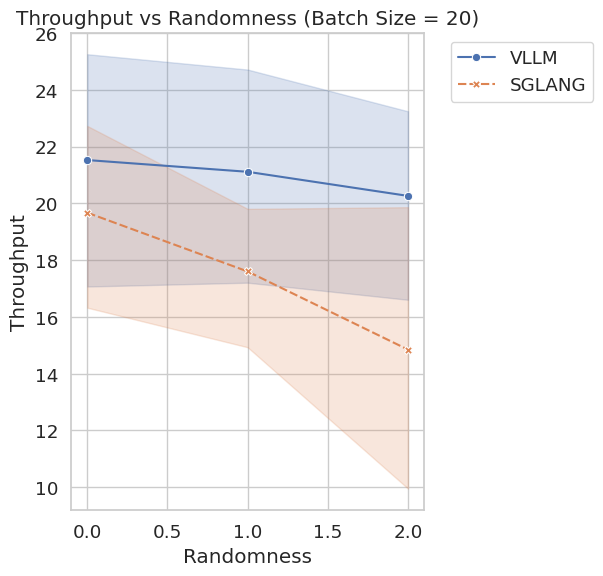

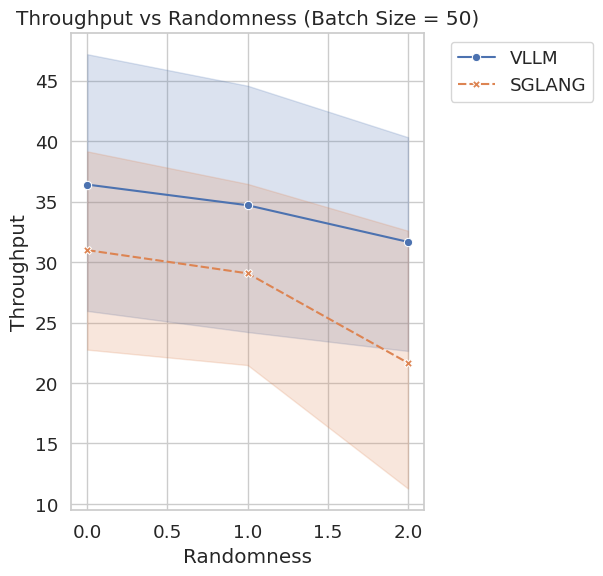

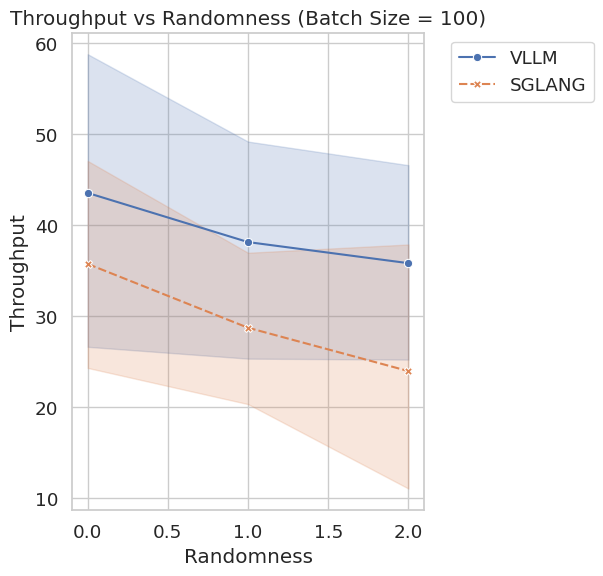

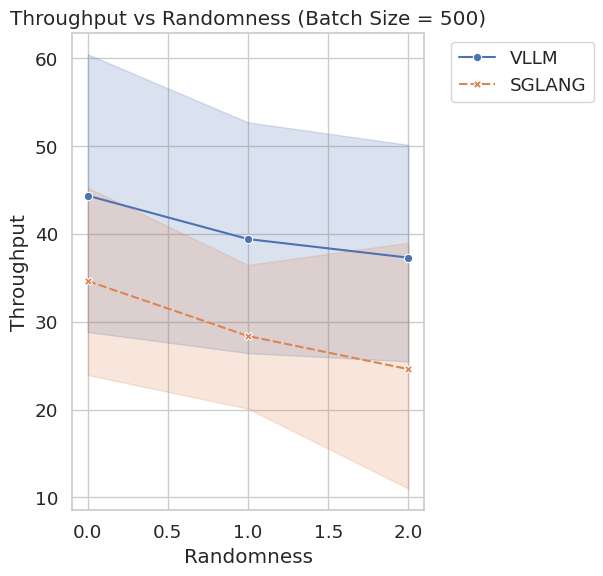

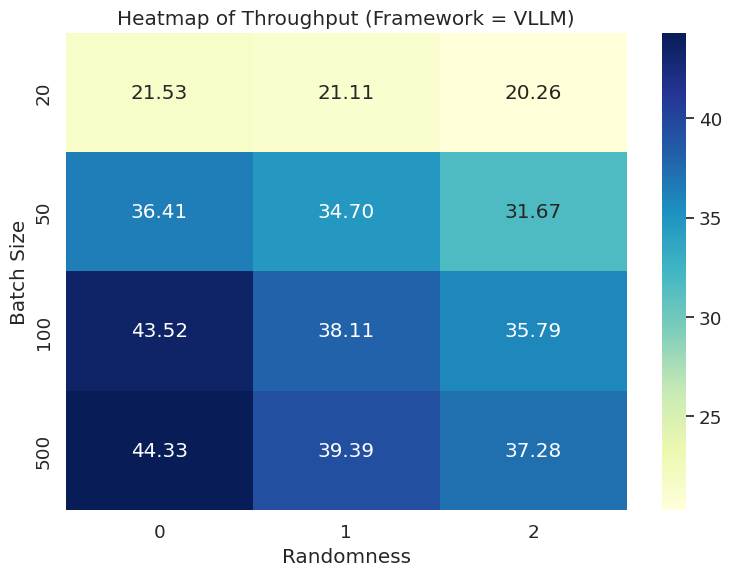

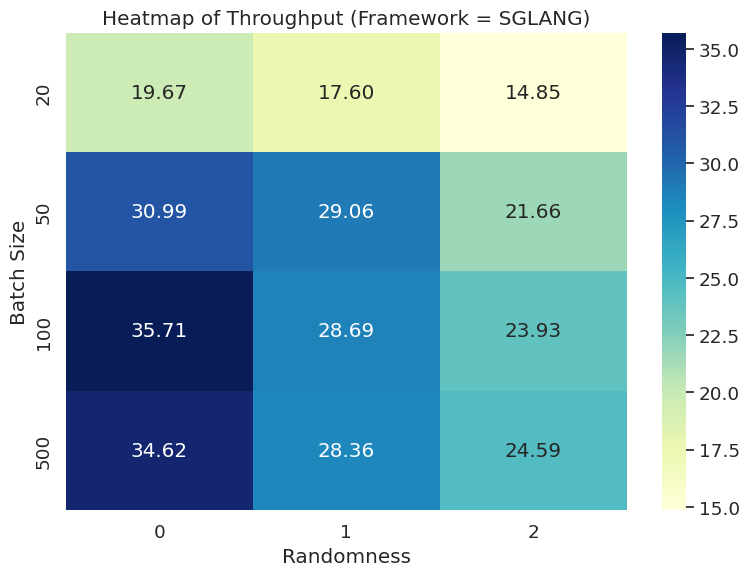

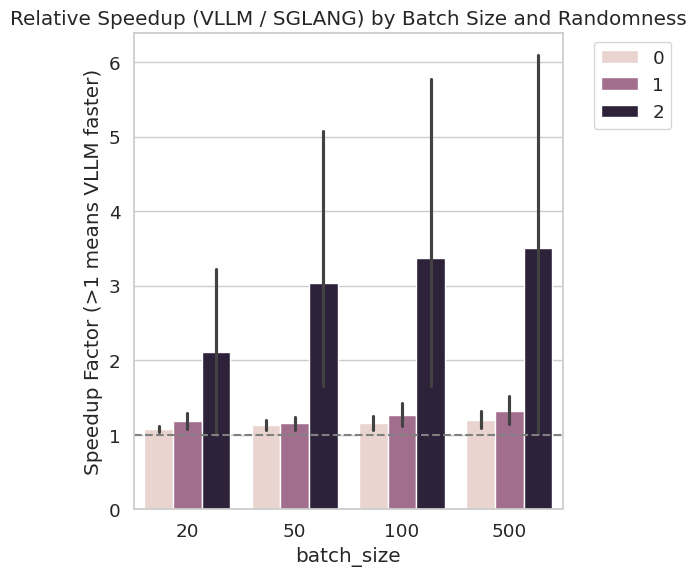

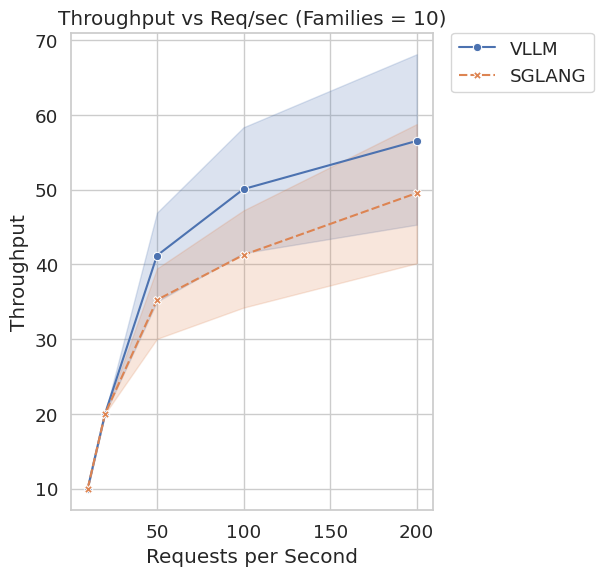

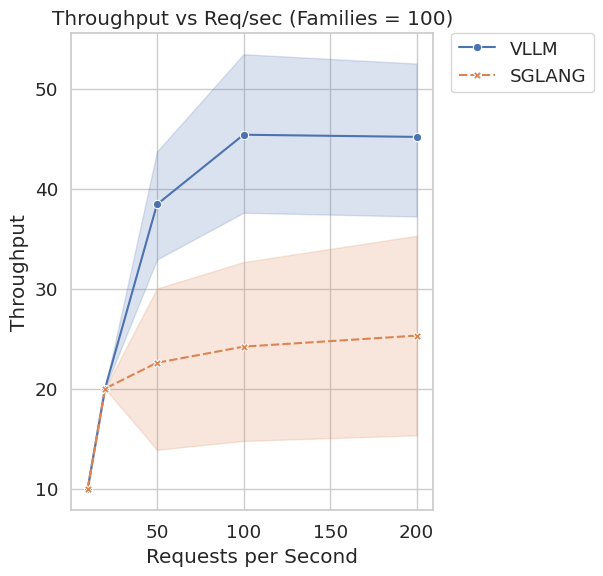

In [11]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------------- READ AND PARSE ----------------
data = []
pattern_vllm = re.compile(
    r"Throughput Test with (\d+) families, (\d+) req/sec and max_batch_size of (\d+) \(randomness: (\d+)\): ([\d\.]+)"
)
pattern_sglang = re.compile(
    r"Throughput Test with (\d+) families, (\d+) req/sec and max_batch_size of (\d+) \(randomness: (\d+)\) for SGLANG: ([\d\.]+)"
)

filename = "vllm_sglang_multiple_families_comparison.txt"
with open(filename, "r") as f:
    for line in f:
        line = line.strip()
        m_vllm = pattern_vllm.match(line)
        m_sglang = pattern_sglang.match(line)
        if m_vllm:
            families, req, batch, rand, val = m_vllm.groups()
            data.append([int(families), int(req), int(batch), int(rand), "VLLM", float(val)])
        elif m_sglang:
            families, req, batch, rand, val = m_sglang.groups()
            data.append([int(families), int(req), int(batch), int(rand), "SGLANG", float(val)])

df = pd.DataFrame(data, columns=["families", "req_per_sec", "batch_size", "randomness", "framework", "throughput"])
# ---------------- ADD SYNTHETIC ROWS ----------------
extra_rows = []
for families in df["families"].unique():
    for batch in df["batch_size"].unique():
        for rand in df["randomness"].unique():
            for framework in ["VLLM", "SGLANG"]:
                extra_rows.append([families, 10, batch, rand, framework, 10.0])
                extra_rows.append([families, 20, batch, rand, framework, 20.0])

df_extra = pd.DataFrame(extra_rows, columns=df.columns)

# Combine with original data
df = pd.concat([df, df_extra], ignore_index=True)
print(df.head())

sns.set(style="whitegrid", font_scale=1.2)

# ---------------- FILTER (OPTIONAL) ----------------
# Uncomment to restrict to one number of families (e.g., 100)
# df = df[df["families"] == 100]

# ---------------- HELPER FUNCTION FOR LEGEND ----------------
def finalize_plot(title):
    plt.title(title)
    plt.xlabel("Requests per Second")
    plt.ylabel("Throughput")
    plt.grid(True)
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", borderaxespad=0.)
    plt.tight_layout(rect=[0, 0, 0.8, 1])

# ============================================================
# 1️⃣ Throughput vs Req/sec — per batch size, both frameworks
# ============================================================
for b in sorted(df["batch_size"].unique()):
    plt.figure(figsize=(8,6))
    subset = df[df["batch_size"] == b]
    sns.lineplot(data=subset, x="req_per_sec", y="throughput", hue="framework", style="framework", markers=True)
    finalize_plot(f"Throughput vs Req/sec (Batch Size = {b})")
    plt.show()

# ============================================================
# 2️⃣ Throughput vs Batch Size — for each randomness level
# ============================================================
for r in sorted(df["randomness"].unique()):
    plt.figure(figsize=(8,6))
    subset = df[df["randomness"] == r]
    sns.barplot(data=subset, x="batch_size", y="throughput", hue="framework")
    plt.title(f"Throughput vs Batch Size (Randomness = {r})")
    plt.ylabel("Throughput")
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout(rect=[0, 0, 0.8, 1])
    plt.show()

# ============================================================
# 3️⃣ Throughput vs Randomness — for each batch size
# ============================================================
for b in sorted(df["batch_size"].unique()):
    plt.figure(figsize=(8,6))
    subset = df[df["batch_size"] == b]
    sns.lineplot(data=subset, x="randomness", y="throughput", hue="framework", style="framework", markers=True)
    plt.title(f"Throughput vs Randomness (Batch Size = {b})")
    plt.xlabel("Randomness")
    plt.ylabel("Throughput")
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout(rect=[0, 0, 0.8, 1])
    plt.show()

# ============================================================
# 4️⃣ Heatmap Comparison — Batch Size × Randomness
# ============================================================
for fw in df["framework"].unique():
    pivot = df[df["framework"] == fw].pivot_table(
        values="throughput", index="batch_size", columns="randomness", aggfunc="mean"
    )
    plt.figure(figsize=(8,6))
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu")
    plt.title(f"Heatmap of Throughput (Framework = {fw})")
    plt.ylabel("Batch Size")
    plt.xlabel("Randomness")
    plt.tight_layout()
    plt.show()

# ============================================================
# 5️⃣ Relative Speedup (VLLM / SGLANG)
# ============================================================
pivot_ratio = (
    df.pivot_table(index=["families", "req_per_sec", "batch_size", "randomness"],
                   columns="framework", values="throughput")
    .reset_index()
)
pivot_ratio["speedup"] = pivot_ratio["VLLM"] / pivot_ratio["SGLANG"]

plt.figure(figsize=(8,6))
sns.barplot(data=pivot_ratio, x="batch_size", y="speedup", hue="randomness")
plt.axhline(1, color="gray", linestyle="--")
plt.title("Relative Speedup (VLLM / SGLANG) by Batch Size and Randomness")
plt.ylabel("Speedup Factor (>1 means VLLM faster)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout(rect=[0, 0, 0.8, 1])
plt.show()

# ============================================================
# 6️⃣ Optional: Per-family Throughput Comparison
# ============================================================
for fam in sorted(df["families"].unique()):
    plt.figure(figsize=(8,6))
    subset = df[df["families"] == fam]
    sns.lineplot(data=subset, x="req_per_sec", y="throughput", hue="framework", style="framework", markers=True)
    finalize_plot(f"Throughput vs Req/sec (Families = {fam})")
    plt.show()
